# Ajuste del modelo del motor DC

**Control Inteligente II (168418) · Universidad de Pamplona · Ing. Jeisson Martínez Flórez**

Este notebook toma los datos que imprime el firmware de identificación y entrega el modelo de cada motor:

| Parámetro | Qué es | De qué ensayo sale |
|---|---|---|
| K [RPM/PWM] y B [RPM] | Recta estática, RPM ≈ K·PWM − B | Escaleras (`x`) |
| Zona muerta [PWM] | PWM mínimo con el que la rueda gira de forma sostenida | Escaleras (`x`) |
| τ [ms] y L [ms] | Constante de tiempo y retardo del primer orden | Escalones (`s`) |

**Cómo se usa.** En la celda 0 cambie `GRUPO` y `RUTA_DATOS` por los de su grupo y ejecute todo (*Run All*). En la carpeta pueden estar los bloques CSV copiados del monitor o el archivo completo que guarda `log2file`. El notebook encuentra solo cada bloque entre `INICIO_CSV` y `FIN_CSV`.

> Los datos de `datos/ejemplo_sintetico` salen de un modelo de motor simulado. Sirven para probar el notebook, **no son medidas de un robot real**.

## 0. Configuración

In [29]:
from pathlib import Path
import json
import datetime as dt

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# ---- Lo único que cambia cada grupo ----
GRUPO = "G2"                                  # p. ej. "G3"
RUTA_DATOS = Path("../datos/G2")    # carpeta con los .csv o .log del monitor
RUTA_RESULTADOS = Path("../resultados")

# ---- Parámetros del análisis (se dejan así) ----
VENTANA_AJUSTE_MS = 250    # tiempo después de cada cambio de PWM que se usa para ajustar τ y L
VENTANA_RPM_MS = 10        # ventana para calcular la RPM que se grafica
RPM_GIRO = 1.0             # por encima de esto se considera que la rueda gira (recta estática)
RPM_ARRANQUE = 0.5         # primer peldaño con más que esto = zona muerta

# Colores de las gráficas (paleta validada para daltonismo)
AZUL, NARANJA, VERDE_AGUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.grid": True, "grid.color": "#e3e2de", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS,
    "axes.labelcolor": "#0b0b0b", "xtick.color": GRIS, "ytick.color": GRIS,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
print("Datos en:", RUTA_DATOS)

Datos en: ..\datos\G2


## 1. Lectura de los datos

Cada bloque del firmware tiene una línea de descripción que empieza con `#` y luego las columnas `t_us, uL, uR, cL, cR`:

- `t_us` es el tiempo desde el inicio del ensayo, en microsegundos.
- `uL` y `uR` son el PWM aplicado a cada motor desde esa muestra.
- `cL` y `cR` son las cuentas acumuladas de cada encoder.

In [31]:
def leer_descripcion(linea):
    """'# ensayo=escalon motor=R base=0 ...' -> {'ensayo': 'escalon', 'motor': 'R', 'base': 0, ...}"""
    meta = {}
    for par in linea.lstrip("#").split():
        if "=" in par:
            clave, valor = par.split("=", 1)
            try:
                meta[clave] = float(valor) if any(c in valor for c in ".eE") else int(valor)
            except ValueError:
                meta[clave] = valor
    return meta


def leer_bloques(texto, origen):
    """Encuentra todos los ensayos de un texto (un CSV copiado o el log completo del monitor)."""
    ensayos, filas, meta, dentro = [], [], None, False
    lineas = texto.splitlines()
    sin_marcas = "INICIO_CSV" not in texto            # el estudiante copió solo el bloque
    for linea in lineas:
        linea = linea.strip()
        if linea == "INICIO_CSV" or (sin_marcas and linea.startswith("# ensayo=")):
            if dentro and meta is not None and filas:  # bloque anterior sin FIN_CSV
                ensayos.append((meta, filas))
            dentro, filas, meta = True, [], None
            if sin_marcas:
                meta = leer_descripcion(linea)
            continue
        if not dentro:
            continue
        if linea == "FIN_CSV":
            if meta is not None and filas:
                ensayos.append((meta, filas))
            dentro = False
            continue
        if linea.startswith("# ensayo="):
            meta = leer_descripcion(linea)
        elif linea and linea[0].isdigit():
            partes = linea.split(",")
            if len(partes) == 5:
                filas.append([float(p) for p in partes])
    if dentro and meta is not None and filas:
        ensayos.append((meta, filas))

    resultado = []
    for meta, filas in ensayos:
        d = np.array(filas)
        meta["origen"] = origen
        resultado.append({
            "meta": meta,
            "t": (d[:, 0] - d[0, 0]) * 1e-6,           # [s]
            "u": {"L": d[:, 1].astype(int), "R": d[:, 2].astype(int)},
            "c": {"L": d[:, 3], "R": d[:, 4]},
            "cpv": {"L": float(meta.get("cuentas_vuelta_L", 1)), "R": float(meta.get("cuentas_vuelta_R", 1))},
        })
    return resultado


archivos = sorted(p for p in RUTA_DATOS.glob("*") if p.suffix.lower() in (".csv", ".log", ".txt"))
ensayos = []
for p in archivos:
    ensayos += leer_bloques(p.read_text(encoding="utf-8", errors="replace"), p.name)

print(f"{len(archivos)} archivos, {len(ensayos)} ensayos\n")
print(f"{'#':>3}  {'ensayo':9} {'motor':5} {'parámetros':22} {'batería':>8} {'muestras':>8} {'errores L/R':>12}  origen")
for i, e in enumerate(ensayos):
    m = e["meta"]
    if m.get("ensayo") == "escalon":
        par = f"base {m['base']} -> {m['escalon']}"
    else:
        par = f"{m.get('ini')} paso {m.get('paso')} x {m.get('peldanos')}"
    print(f"{i:>3}  {m.get('ensayo',''):9} {m.get('motor',''):5} {par:22} {m.get('bateria_V', 0):>6.2f} V "
          f"{len(e['t']):>8} {m.get('errores_L',0):>5}/{m.get('errores_R',0):<5}  {m['origen']}")

1 archivos, 16 ensayos

  #  ensayo    motor parámetros              batería muestras  errores L/R  origen
  0  escalera  L     10 paso 5 x 14          10.50 V     1121     0/0      G2.log
  1  escalera  L     -10 paso -4 x 14        10.50 V     1121     0/0      G2.log
  2  escalon   L     base 0 -> 60            10.50 V     1251     0/0      G2.log
  3  escalon   L     base 0 -> 120           10.50 V     1251     0/0      G2.log
  4  escalon   L     base 0 -> 200           10.50 V     1251     0/0      G2.log
  5  escalon   L     base 60 -> 120          10.50 V     1251     0/0      G2.log
  6  escalon   L     base 0 -> -120          10.50 V     1251     0/0      G2.log
  7  escalon   L     base -60 -> -120        10.50 V     1251     0/0      G2.log
  8  escalera  R     10 paso 5 x 14          10.50 V     1121     0/0      G2.log
  9  escalera  R     10 paso 5 x 14          10.50 V     1121     0/0      G2.log
 10  escalon   R     base 0 -> 60            10.50 V     1251     0/0    

## 2. Funciones de apoyo

La RPM no se mide directamente. Sale de las cuentas: **RPM = (cuentas giradas / cuentas por vuelta) / tiempo × 60**.

Es importante que tengan en cuenta que con muestras cada 2 ms una sola cuenta de diferencia ya cambia mucho la RPM. Con 2618 cuentas por vuelta, una cuenta en 2 ms equivale a 11,5 RPM. Por eso aquí la RPM siempre se calcula sobre una ventana de tiempo y, para ajustar el modelo, se usan las cuentas acumuladas, que no tienen ese ruido.

In [32]:
def rpm_media(e, lado, i0, i1):
    """RPM media entre las muestras i0 e i1, con las cuentas acumuladas."""
    dt_s = e["t"][i1] - e["t"][i0]
    return (e["c"][lado][i1] - e["c"][lado][i0]) / e["cpv"][lado] / dt_s * 60 if dt_s > 0 else 0.0


def rpm_ventana(e, lado, ventana_ms=VENTANA_RPM_MS):
    """RPM con una ventana centrada (para graficar)."""
    t, c = e["t"], e["c"][lado]
    ts = np.median(np.diff(t))
    h = max(1, int(round(ventana_ms * 1e-3 / ts / 2)))
    rpm = np.full(len(t), np.nan)
    rpm[h:-h] = (c[2 * h:] - c[:-2 * h]) / e["cpv"][lado] / (t[2 * h:] - t[:-2 * h]) * 60
    return rpm


def tramos(e, lado):
    """Intervalos con el mismo PWM: lista de (i_inicio, i_fin, pwm). La última muestra cierra el último tramo."""
    u = e["u"][lado][:-1]
    cortes = np.flatnonzero(np.diff(u)) + 1
    inicios = np.concatenate(([0], cortes))
    fines = np.concatenate((cortes, [len(u)]))
    return [(int(a), int(b), int(u[a])) for a, b in zip(inicios, fines)]


def motores_del_ensayo(e):
    m = e["meta"].get("motor", "A")
    return ["L", "R"] if m == "A" else [m]

## 3. Recta estática y zona muerta (escaleras)

En cada peldaño de la escalera el PWM se deja fijo 400 ms. Entonces, lo que hacemos es tomar la RPM media de la **segunda mitad** de cada peldaño, cuando la rueda ya se estabilizó. Con esos puntos se ajusta por mínimos cuadrados la recta

$$|RPM| = K\,|PWM| - B$$

usando solo los peldaños donde la rueda gira (más de 1 RPM). La zona muerta es el primer peldaño donde la rueda gira de forma sostenida. Se ajusta por separado hacia adelante y hacia atrás, porque los dos sentidos no tienen por qué ser iguales.

In [33]:
puntos = {"L": [], "R": []}          # (pwm, rpm) de todos los peldaños
for e in ensayos:
    if e["meta"].get("ensayo") != "escalera":
        continue
    for lado in motores_del_ensayo(e):
        for i0, i1, u in tramos(e, lado):
            puntos[lado].append((u, rpm_media(e, lado, (i0 + i1) // 2, i1)))

estatico = {}
for lado in "LR":
    p = np.array(puntos[lado])
    if len(p) == 0:
        continue
    for sentido, signo in (("adelante", 1), ("atras", -1)):
        q = p[np.sign(p[:, 0]) == signo]
        if len(q) == 0:
            continue
        x, y = np.abs(q[:, 0]), np.abs(q[:, 1])
        orden = np.argsort(x)
        x, y = x[orden], y[orden]
        gira = y >= RPM_GIRO
        arranca = x[y >= RPM_ARRANQUE]
        if gira.sum() < 3:
            print(f"Rueda {lado} {sentido}: menos de 3 peldaños con giro, no se ajusta.")
            continue
        K, c0 = np.polyfit(x[gira], y[gira], 1)
        residuo = y[gira] - (K * x[gira] + c0)
        estatico[(lado, sentido)] = {"K": K, "B": -c0, "zona_muerta": int(arranca.min()) if len(arranca) else None,
                                      "rms_rpm": float(np.sqrt(np.mean(residuo ** 2))), "n": int(gira.sum())}

print(f"{'rueda':6} {'sentido':9} {'K [RPM/PWM]':>12} {'B [RPM]':>8} {'zona muerta':>12} {'error RMS':>10} {'peldaños':>9}")
for (lado, sentido), r in estatico.items():
    print(f"{lado:6} {sentido:9} {r['K']:>12.3f} {r['B']:>8.2f} {str(r['zona_muerta']):>12} {r['rms_rpm']:>8.2f} RPM {r['n']:>6}")

rueda  sentido    K [RPM/PWM]  B [RPM]  zona muerta  error RMS  peldaños
L      adelante         0.357     2.51           10     0.19 RPM     14
L      atras            0.344     2.16           14     0.06 RPM     13
R      adelante         0.381     2.09           15     0.04 RPM     26


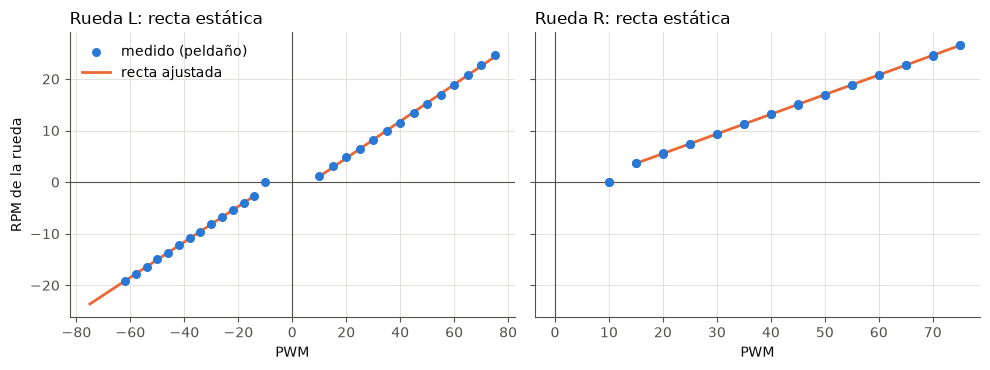

In [34]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, lado in zip(ejes, "LR"):
    p = np.array(puntos[lado]) if puntos[lado] else np.empty((0, 2))
    ax.scatter(p[:, 0], p[:, 1], s=30, color=AZUL, label="medido (peldaño)", zorder=3)
    for sentido, signo in (("adelante", 1), ("atras", -1)):
        r = estatico.get((lado, sentido))
        if r is None:
            continue
        x = np.linspace(r["zona_muerta"] or 0, np.abs(p[:, 0]).max(), 50)
        ax.plot(signo * x, signo * (r["K"] * x - r["B"]), color=NARANJA,
                label="recta ajustada" if signo == 1 else None)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.axvline(0, color=GRIS, lw=0.8)
    ax.set_title(f"Rueda {lado}: recta estática", loc="left")
    ax.set_xlabel("PWM")
ejes[0].set_ylabel("RPM de la rueda")
ejes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

## 4. Dinámica (escalones): primer orden con retardo, ajustado sobre las cuentas

Después de cada cambio de PWM, de u₀ a u₁, la RPM se modela como un sistema de primer orden con retardo (FOPDT):

$$RPM(t) = r_0 + (r_1 - r_0)\left(1 - e^{-(t-L)/\tau}\right),\qquad t \ge L$$

- r₀ es la RPM antes del cambio (media de los 60 ms previos).
- r₁ es la RPM final (media de la segunda mitad del tramo).
- τ y L se buscan por mínimos cuadrados.

Resulta que la RPM derivada de las cuentas a 2 ms es muy gruesa. Entonces, en lugar de comparar RPM, se compara **la integral del modelo con las cuentas medidas** durante los 250 ms siguientes al cambio. La integral del modelo tiene forma cerrada:

$$c(t) = c(0) + \frac{\text{cuentas/vuelta}}{60}\Big[r_0\,t + (r_1-r_0)\big((t-L) - \tau\,(1-e^{-(t-L)/\tau})\big)\Big]$$

Como verificación se calcula también τ por el **método del área**, el mismo del firmware: τ + L = (r₁·T − ∫RPM dt)/(r₁ − r₀). Los dos valores deben dar parecido.

In [12]:
def cuentas_modelo(t, r0, r1, tau, L, cpv):
    s = np.clip(t - L, 0, None)
    integral = r0 * t + (r1 - r0) * (s - tau * (1 - np.exp(-s / tau)))     # [RPM·s]
    return integral * cpv / 60


def ajustar_transicion(e, lado, i_cambio, i_fin):
    t, c, cpv = e["t"], e["c"][lado], e["cpv"][lado]
    ts = np.median(np.diff(t))
    n60 = max(2, int(0.060 / ts))
    r0 = rpm_media(e, lado, max(0, i_cambio - n60), i_cambio)
    r1 = rpm_media(e, lado, (i_cambio + i_fin) // 2, i_fin)
    if abs(r1 - r0) < 2:
        return None
    iT = min(i_fin, i_cambio + int(VENTANA_AJUSTE_MS * 1e-3 / ts))
    tt = t[i_cambio:iT + 1] - t[i_cambio]
    cc = c[i_cambio:iT + 1] - c[i_cambio]

    def error(p):
        return cuentas_modelo(tt, r0, r1, p[0], p[1], cpv) - cc

    sol = least_squares(error, x0=[0.020, 0.002], bounds=([0.001, 0.0], [0.300, 0.040]))
    tau, L = sol.x
    T = tt[-1]
    tau_area = (r1 * T - cc[-1] / cpv * 60) / (r1 - r0)          # τ + L por el método del área
    return {"r0": r0, "r1": r1, "tau": tau, "L": L, "tau_area": tau_area,
            "rms_cuentas": float(np.sqrt(np.mean(sol.fun ** 2))), "tt": tt, "cc": cc}


transiciones = []
for k, e in enumerate(ensayos):
    if e["meta"].get("ensayo") != "escalon":
        continue
    for lado in motores_del_ensayo(e):
        tr = tramos(e, lado)
        for j in range(1, len(tr)):
            i_cambio, i_fin, u1 = tr[j]
            u0 = tr[j - 1][2]
            r = ajustar_transicion(e, lado, i_cambio, i_fin)
            if r is None:
                continue
            r.update({"ensayo": k, "lado": lado, "u0": u0, "u1": u1, "i_cambio": i_cambio,
                      "K_inc": (r["r1"] - r["r0"]) / (u1 - u0), "frena_a_cero": u1 == 0})
            transiciones.append(r)

print(f"{'#':>3} {'rueda':5} {'PWM':>11} {'RPM':>15} {'K inc.':>7} {'τ [ms]':>7} {'L [ms]':>7} "
      f"{'τ+L área':>9} {'error':>8}")
for r in transiciones:
    nota = "  (freno en corto)" if r["frena_a_cero"] else ""
    print(f"{r['ensayo']:>3} {r['lado']:5} {r['u0']:>4} -> {r['u1']:<4} {r['r0']:>6.1f} -> {r['r1']:<6.1f} "
          f"{r['K_inc']:>7.3f} {r['tau']*1e3:>7.1f} {r['L']*1e3:>7.1f} {r['tau_area']*1e3:>9.1f} "
          f"{r['rms_cuentas']:>5.2f} ct{nota}")

  # rueda         PWM             RPM  K inc.  τ [ms]  L [ms]  τ+L área    error
  2 L        0 -> 60      0.0 -> 18.8     0.313    24.6     0.0      25.8  1.04 ct
  2 L       60 -> 0      18.5 -> 0.0      0.309    12.2     4.5      16.7  0.30 ct  (freno en corto)
  3 L        0 -> 120     0.0 -> 41.3     0.344    26.9     0.0      27.9  1.73 ct
  3 L      120 -> 0      41.5 -> 0.0      0.346    16.6     2.8      19.3  0.49 ct  (freno en corto)
  4 L        0 -> 200     0.0 -> 72.1     0.360    29.5     0.0      30.6  2.54 ct
  4 L      200 -> 0      72.3 -> 0.0      0.361    17.9     2.9      20.7  0.65 ct  (freno en corto)
  5 L       60 -> 120    19.5 -> 41.9     0.374    28.3     0.0      29.3  0.95 ct
  5 L      120 -> 60     42.1 -> 19.6     0.376    31.6     0.0      32.0  0.39 ct
  6 L        0 -> -120    0.0 -> -41.0    0.342    24.4     0.0      25.1  1.23 ct
  6 L     -120 -> 0     -40.9 -> 0.0      0.341    17.0     2.7      19.6  0.32 ct  (freno en corto)
  7 L      -60 ->

**Cómo leer la tabla.** La columna *error* es el error RMS del ajuste, en cuentas. Si es menor que una o dos cuentas, el modelo de primer orden explica casi todo lo medido. Lo que queda es la cuantización del encoder.

Ahora miremos una transición en detalle. Cambie `ver` para revisar otra fila de la tabla.

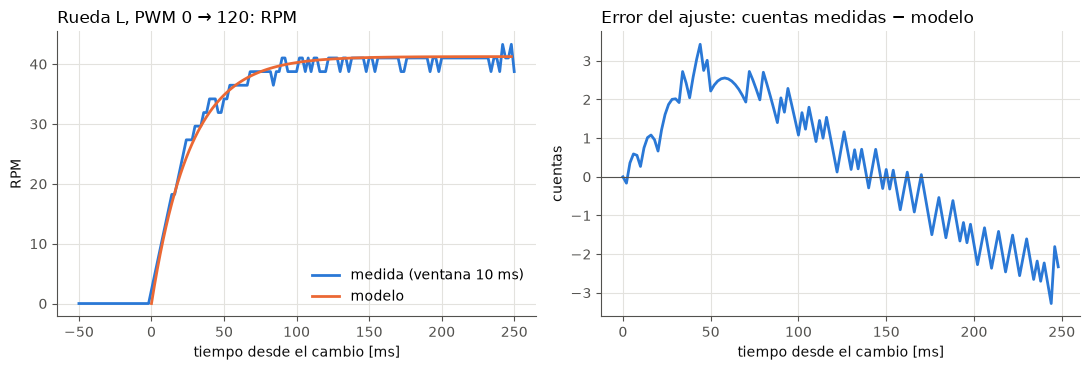

τ = 26.9 ms, L = 0.0 ms, τ + L por área = 27.9 ms


In [13]:
ver = 2    # fila de la tabla de transiciones (0 = primera fila)

r = transiciones[ver]
e = ensayos[r["ensayo"]]
cpv = e["cpv"][r["lado"]]
tt, cc = r["tt"], r["cc"]
modelo = cuentas_modelo(tt, r["r0"], r["r1"], r["tau"], r["L"], cpv)

# RPM medida (ventana) y RPM del modelo, con el tiempo contado desde el cambio de PWM
t, rpm = e["t"], rpm_ventana(e, r["lado"])
t_rel = t - t[r["i_cambio"]]
s = np.clip(tt - r["L"], 0, None)
rpm_mod = r["r0"] + (r["r1"] - r["r0"]) * (1 - np.exp(-s / r["tau"]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
ventana = (t_rel > -0.05) & (t_rel < VENTANA_AJUSTE_MS * 1e-3)
a1.plot(t_rel[ventana] * 1e3, rpm[ventana], color=AZUL, label=f"medida (ventana {VENTANA_RPM_MS} ms)")
a1.plot(tt * 1e3, rpm_mod, color=NARANJA, label="modelo")
a1.set_title(f"Rueda {r['lado']}, PWM {r['u0']} → {r['u1']}: RPM", loc="left")
a1.set_xlabel("tiempo desde el cambio [ms]")
a1.set_ylabel("RPM")
a1.legend(loc="best")

a2.plot(tt * 1e3, cc - modelo, color=AZUL)
a2.axhline(0, color=GRIS, lw=0.8)
a2.set_title("Error del ajuste: cuentas medidas − modelo", loc="left")
a2.set_xlabel("tiempo desde el cambio [ms]")
a2.set_ylabel("cuentas")
plt.tight_layout()
plt.show()
print(f"τ = {r['tau']*1e3:.1f} ms, L = {r['L']*1e3:.1f} ms, τ + L por área = {r['tau_area']*1e3:.1f} ms")

## 5. Resumen del modelo de cada motor

- **K y B** salen de la recta estática (escaleras), **una recta por sentido**.
- **τ** es la mediana de las transiciones que **no** terminan en PWM 0. Esa es la dinámica que va a ver el lazo de RPM, que casi siempre trabaja lejos de cero.
- **L** (retardo) sale de esas mismas transiciones. Las que terminan en PWM 0 dan la τ de freno y el retardo de freno, y se reportan aparte.
- Como verificación, la K incremental de los escalones con la rueda ya girando debe parecerse a la K de la recta **del mismo sentido**. Desde parado sale menor, porque la recta no pasa por el origen.

**Criterio de K para el firmware: por sentido.** El lazo de RPM usa K, B y zona muerta de adelante cuando la consigna es positiva, y los de atrás cuando es negativa. El PI y la validación usan el mismo criterio. El JSON guarda también la recta **promediada** (K y B promedio de los dos sentidos), pero solo para comparar. En el equilibrio la rueda cambia de sentido todo el tiempo, y con la recta promediada la prealimentación queda corrida en uno de los dos sentidos.

In [14]:
def media(*v):
    v = [x for x in v if x is not None]
    return float(np.mean(v)) if v else None


modelo_motor = {}
for lado in "LR":
    tl = [r for r in transiciones if r["lado"] == lado]
    if not tl:
        continue
    acel = [r for r in tl if not r["frena_a_cero"]]      # τ y L: las que NO terminan en PWM 0
    freno = [r for r in tl if r["frena_a_cero"]]         # freno en corto: se reporta aparte
    ad, at = estatico.get((lado, "adelante"), {}), estatico.get((lado, "atras"), {})
    girando_ad = [r["K_inc"] for r in acel if r["u0"] > 0 and r["u1"] > 0]
    girando_at = [r["K_inc"] for r in acel if r["u0"] < 0 and r["u1"] < 0]
    zm_prom = media(ad.get("zona_muerta"), at.get("zona_muerta"))
    modelo_motor[lado] = {
        # Criterio del firmware: una recta por sentido
        "K_adelante": ad.get("K"), "B_adelante_rpm": ad.get("B"), "zona_muerta_adelante_pwm": ad.get("zona_muerta"),
        "K_atras": at.get("K"), "B_atras_rpm": at.get("B"), "zona_muerta_atras_pwm": at.get("zona_muerta"),
        # Solo para comparar: la recta promediada de los dos sentidos
        "K_promedio": media(ad.get("K"), at.get("K")), "B_promedio_rpm": media(ad.get("B"), at.get("B")),
        "zona_muerta_promedio_pwm": int(round(zm_prom)) if zm_prom is not None else None,
        # Dinámica
        "tau_s": float(np.median([r["tau"] for r in acel])) if acel else None,
        "retardo_s": float(np.median([r["L"] for r in acel])) if acel else None,
        "tau_freno_s": float(np.median([r["tau"] for r in freno])) if freno else None,
        "retardo_freno_s": float(np.median([r["L"] for r in freno])) if freno else None,
        # Verificación
        "K_incremental_girando_adelante": media(*girando_ad),
        "K_incremental_girando_atras": media(*girando_at),
        "cuentas_vuelta": ensayos[tl[0]["ensayo"]]["cpv"][lado],
    }


def ms(v):
    return f"{v*1e3:.1f} ms" if v is not None else "—"


for lado, m in modelo_motor.items():
    print(f"Rueda {lado}")
    print(f"  Recta:      adelante RPM = {m['K_adelante']:.3f}·PWM − {m['B_adelante_rpm']:.2f}  (arranca con {m['zona_muerta_adelante_pwm']})")
    if m["K_atras"] is not None:
        print(f"              atrás    RPM = {m['K_atras']:.3f}·PWM − {m['B_atras_rpm']:.2f}  (arranca con {m['zona_muerta_atras_pwm']})")
        dif = 100 * (m["K_atras"] - m["K_adelante"]) / m["K_adelante"]
        print(f"              promedio RPM = {m['K_promedio']:.3f}·PWM − {m['B_promedio_rpm']:.2f}  "
              f"(solo para comparar; K de atrás {dif:+.1f} % frente a la de adelante)")
    print(f"  Dinámica:   τ = {ms(m['tau_s'])} · retardo = {ms(m['retardo_s'])}   "
          f"(freno: τ = {ms(m['tau_freno_s'])}, retardo = {ms(m['retardo_freno_s'])})")
    for sentido, clave_inc, clave_k in (("adelante", "K_incremental_girando_adelante", "K_adelante"),
                                        ("atrás", "K_incremental_girando_atras", "K_atras")):
        if m[clave_inc] is not None and m[clave_k]:
            dif = 100 * (m[clave_inc] - m[clave_k]) / m[clave_k]
            print(f"  Verificación {sentido}: K incremental girando = {m[clave_inc]:.3f} ({dif:+.1f} % frente a la recta de {sentido})")
    rpm_max = m["K_adelante"] * 255 - m["B_adelante_rpm"]
    print(f"  RPM máxima estimada con PWM 255: {rpm_max:.1f} RPM\n")

Rueda L
  Recta:      adelante RPM = 0.357·PWM − 2.51  (arranca con 10)
              atrás    RPM = 0.344·PWM − 2.16  (arranca con 14)
              promedio RPM = 0.351·PWM − 2.33  (solo para comparar; K de atrás -3.7 % frente a la de adelante)
  Dinámica:   τ = 28.2 ms · retardo = 0.0 ms   (freno: τ = 16.8 ms, retardo = 2.9 ms)
  Verificación adelante: K incremental girando = 0.375 (+4.9 % frente a la recta de adelante)
  Verificación atrás: K incremental girando = 0.372 (+8.2 % frente a la recta de atrás)
  RPM máxima estimada con PWM 255: 88.6 RPM

Rueda R
  Recta:      adelante RPM = 0.381·PWM − 2.09  (arranca con 15)
  Dinámica:   τ = 23.7 ms · retardo = 0.0 ms   (freno: τ = 14.7 ms, retardo = 3.3 ms)
  Verificación adelante: K incremental girando = 0.384 (+0.7 % frente a la recta de adelante)
  RPM máxima estimada con PWM 255: 95.1 RPM



## 6. Validación: el modelo frente a un ensayo completo

Un modelo no se da por bueno porque ajuste los datos con los que se construyó. Lo que hacemos es simularlo con la secuencia de PWM de una escalera y comparar la RPM que predice con la medida.

El modelo completo tiene tres partes:
1. la zona muerta y la recta estática;
2. el primer orden con τ, o con τ de freno cuando el PWM es 0;
3. el retardo L, o el retardo de freno cuando el PWM es 0.

La simulación se hace con los dos criterios de K. La línea continua es el criterio del firmware (**por sentido**) y la punteada es la recta **promediada**. Si las dos dan casi el mismo error, su motor es simétrico. Si la promediada se aleja en un sentido, ese es el error que la prealimentación cometería con ella.

Es importante tener en cuenta que K y B salieron de estas mismas escaleras. Aquí solo τ y L se prueban con datos independientes.

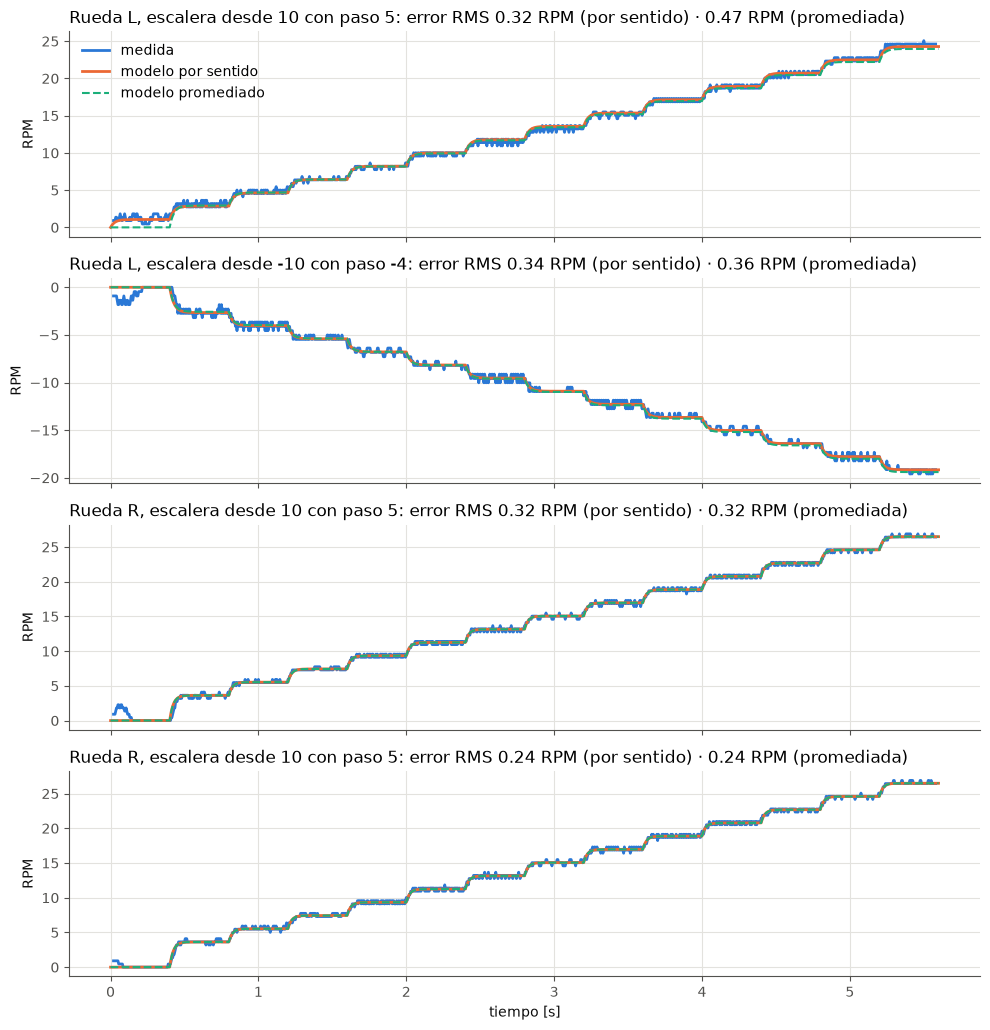

rueda  escalera              por sentido  promediada
L      desde 10, paso 5         0.32 RPM    0.47 RPM
L      desde -10, paso -4       0.34 RPM    0.36 RPM
R      desde 10, paso 5         0.32 RPM    0.32 RPM
R      desde 10, paso 5         0.24 RPM    0.24 RPM


In [15]:
def recta(m, uk, criterio):
    """(K, B, zona muerta) que corresponden al PWM uk según el criterio."""
    if criterio == "promediada":
        return m["K_promedio"], m["B_promedio_rpm"], m["zona_muerta_promedio_pwm"]
    if uk >= 0 or m["K_atras"] is None:
        return m["K_adelante"], m["B_adelante_rpm"], m["zona_muerta_adelante_pwm"]
    return m["K_atras"], m["B_atras_rpm"], m["zona_muerta_atras_pwm"]


def simular(e, lado, m, criterio="por_sentido"):
    """Simula la RPM con el modelo, paso a paso (Euler con 0,1 ms)."""
    t, u = e["t"], e["u"][lado]
    h = 1e-4
    rpm, j = 0.0, 0
    tiempo = np.arange(0, t[-1] + h, h)
    rpm_t = np.zeros(len(tiempo))
    L_mov, L_fre = m["retardo_s"], (m["retardo_freno_s"] if m["retardo_freno_s"] is not None else m["retardo_s"])
    for n, tk in enumerate(tiempo):
        # PWM que ya llegó al motor: el de hace L (L de freno si ese PWM es 0)
        while j + 1 < len(t) and t[j + 1] <= tk - (L_fre if u[j + 1] == 0 else L_mov):
            j += 1
        uk = u[j] if t[j] <= tk - (L_fre if u[j] == 0 else L_mov) else 0
        K, B, zm = recta(m, uk, criterio)
        if uk != 0 and abs(uk) >= (zm or 0):
            objetivo, tau = np.sign(uk) * (K * abs(uk) - B), m["tau_s"]
        else:
            objetivo, tau = 0.0, (m["tau_freno_s"] if uk == 0 else m["tau_s"])
        rpm += (objetivo - rpm) * h / tau
        rpm_t[n] = rpm
    return np.interp(t, tiempo, rpm_t)


validaciones = [e for e in ensayos if e["meta"].get("ensayo") == "escalera"]
errores_validacion = []
fig, ejes = plt.subplots(len(validaciones), 1, figsize=(10, 2.6 * len(validaciones)), sharex=True, squeeze=False)
for ax, e in zip(ejes[:, 0], validaciones):
    lado = motores_del_ensayo(e)[0]
    medida = rpm_ventana(e, lado, ventana_ms=40)
    sim_s = simular(e, lado, modelo_motor[lado], "por_sentido")
    sim_p = simular(e, lado, modelo_motor[lado], "promediada")
    rms_s = np.sqrt(np.nanmean((medida - sim_s) ** 2))
    rms_p = np.sqrt(np.nanmean((medida - sim_p) ** 2))
    errores_validacion.append((lado, e["meta"]["ini"], e["meta"]["paso"], rms_s, rms_p))
    ax.plot(e["t"], medida, color=AZUL, label="medida")
    ax.plot(e["t"], sim_s, color=NARANJA, label="modelo por sentido")
    ax.plot(e["t"], sim_p, color=VERDE_AGUA, ls="--", lw=1.5, label="modelo promediado")
    ax.set_title(f"Rueda {lado}, escalera desde {e['meta']['ini']} con paso {e['meta']['paso']}: "
                 f"error RMS {rms_s:.2f} RPM (por sentido) · {rms_p:.2f} RPM (promediada)", loc="left")
    ax.set_ylabel("RPM")
ejes[0, 0].legend(loc="upper left")
ejes[-1, 0].set_xlabel("tiempo [s]")
plt.tight_layout()
plt.show()

print(f"{'rueda':6} {'escalera':20} {'por sentido':>12} {'promediada':>11}")
for lado, ini, paso, rs, rp in errores_validacion:
    print(f"{lado:6} {f'desde {ini}, paso {paso}':20} {rs:>8.2f} RPM {rp:>7.2f} RPM")

## 7. Lo que sigue: el modelo discreto y el punto de partida del lazo de RPM

Con el modelo, la función de transferencia del motor queda

$$G(s) = \frac{RPM(s)}{PWM(s)} = \frac{K\,e^{-Ls}}{\tau s + 1}$$

y en tiempo discreto, con periodo $T_s$ y sin contar el retardo:

$$RPM[k+1] = a\,RPM[k] + K(1-a)\,PWM[k], \qquad a = e^{-T_s/\tau}$$

En la siguiente sesión esto se usa para diseñar el lazo de RPM. El punto de partida es un PI por cancelación de polo (IMC):

- $T_i = \tau$;
- $K_p = \tau / \big(K(\lambda + L_{total})\big)$, con λ la constante de tiempo que se quiere en lazo cerrado;
- $L_{total}$ suma el retardo del motor, medio periodo del lazo y media ventana de medición de la RPM.

Con el criterio por sentido salen dos Kp por rueda, uno con la K de adelante y otro con la de atrás. La fila «promediada» es solo para comparar.

> **Nombres en el Taller 2.** Desde el Taller 2, la K del motor se llama $K_m$ y el corte B de la recta se llama $N_0$. Así no se confunden con la constante B del modelo del balancín ni con el vector de ganancias K. Las claves del JSON no cambian.

In [17]:
TS_LAZO_S = 0.005        # periodo del lazo de RPM: 5 ms
VENTANA_LAZO_S = 0.010   # ventana de medición de RPM del lazo: 10 ms

for lado, m in modelo_motor.items():
    tau = m["tau_s"]
    L_total = m["retardo_s"] + TS_LAZO_S / 2 + VENTANA_LAZO_S / 2
    print(f"Rueda {lado}:  τ = {tau*1e3:.1f} ms, L_total = {L_total*1e3:.1f} ms "
          f"(retardo {m['retardo_s']*1e3:.1f} + Ts/2 {TS_LAZO_S/2*1e3:.1f} + ventana/2 {VENTANA_LAZO_S/2*1e3:.1f})")
    print(f"  Modelo discreto con la K de adelante:")
    print(f"  {'Ts':>6} {'a':>7} {'K(1−a)':>8}")
    for ts in (0.002, 0.005, 0.010):
        a = np.exp(-ts / tau)
        print(f"  {ts*1e3:>4.0f} ms {a:>7.3f} {m['K_adelante']*(1-a):>8.4f}")
    print(f"  PI de partida, Ti = τ = {tau*1e3:.1f} ms:")
    print(f"    {'criterio':22} {'K [RPM/PWM]':>11}   {'λ = 50 ms: Kp, Ki':>20}   {'λ = 30 ms: Kp, Ki':>20}")
    filas = [("por sentido, adelante", m["K_adelante"]), ("por sentido, atrás", m["K_atras"]),
             ("promediada (comparar)", m["K_promedio"])]
    for nombre, K in filas:
        if K is None:
            continue
        celdas = []
        for lam in (0.050, 0.030):
            kp = tau / (K * (lam + L_total))
            celdas.append(f"{kp:5.2f}, {kp/tau:4.0f}")
        print(f"    {nombre:22} {K:>11.3f}   {celdas[0]:>20}   {celdas[1]:>20}")
    print("    Kp en PWM/RPM y Ki = Kp/τ en PWM/(RPM·s)\n")

Rueda L:  τ = 28.2 ms, L_total = 7.5 ms (retardo 0.0 + Ts/2 2.5 + ventana/2 5.0)
  Modelo discreto con la K de adelante:
      Ts       a   K(1−a)
     2 ms   0.932   0.0244
     5 ms   0.838   0.0579
    10 ms   0.702   0.1065
  PI de partida, Ti = τ = 28.2 ms:
    criterio               K [RPM/PWM]      λ = 50 ms: Kp, Ki      λ = 30 ms: Kp, Ki
    por sentido, adelante        0.357             1.38,   49             2.11,   75
    por sentido, atrás           0.344             1.43,   51             2.19,   78
    promediada (comparar)        0.351             1.40,   50             2.15,   76
    Kp en PWM/RPM y Ki = Kp/τ en PWM/(RPM·s)

Rueda R:  τ = 23.7 ms, L_total = 7.5 ms (retardo 0.0 + Ts/2 2.5 + ventana/2 5.0)
  Modelo discreto con la K de adelante:
      Ts       a   K(1−a)
     2 ms   0.919   0.0309
     5 ms   0.809   0.0726
    10 ms   0.655   0.1314
  PI de partida, Ti = τ = 23.7 ms:
    criterio               K [RPM/PWM]      λ = 50 ms: Kp, Ki      λ = 30 ms: Kp, Ki
   

## 8. Guardar los parámetros

El archivo JSON queda en `resultados/` y es el que se usa en las simulaciones de las próximas sesiones.

In [18]:
bateria = sorted({e["meta"].get("bateria_V", 0) for e in ensayos})
salida = {
    "grupo": GRUPO,
    "fecha": dt.date.today().isoformat(),
    "version": 2,
    "criterio_K_firmware": "por_sentido",
    "nota": ("Recta RPM = K·PWM − B por sentido. tau_s y retardo_s salen de las transiciones que no "
             "terminan en PWM 0. K_promedio y B_promedio_rpm son solo para comparar."),
    "bateria_V": bateria,
    "ensayos": sorted({e["meta"]["origen"] for e in ensayos}),
    "motores": {lado: {k: (round(v, 5) if isinstance(v, float) else v) for k, v in m.items()}
                for lado, m in modelo_motor.items()},
}
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
archivo = RUTA_RESULTADOS / f"parametros_motor_{GRUPO}.json"
archivo.write_text(json.dumps(salida, indent=2, ensure_ascii=False), encoding="utf-8")
print("Guardado en", archivo)
print(json.dumps(salida["motores"], indent=2, ensure_ascii=False))

Guardado en ..\resultados\parametros_motor_G2.json
{
  "L": {
    "K_adelante": 0.35719,
    "B_adelante_rpm": 2.50922,
    "zona_muerta_adelante_pwm": 10,
    "K_atras": 0.34385,
    "B_atras_rpm": 2.15529,
    "zona_muerta_atras_pwm": 14,
    "K_promedio": 0.35052,
    "B_promedio_rpm": 2.33226,
    "zona_muerta_promedio_pwm": 12,
    "tau_s": 0.02825,
    "retardo_s": 0.0,
    "tau_freno_s": 0.0168,
    "retardo_freno_s": 0.00286,
    "K_incremental_girando_adelante": 0.37464,
    "K_incremental_girando_atras": 0.37209,
    "cuentas_vuelta": 3290.9
  },
  "R": {
    "K_adelante": 0.38102,
    "B_adelante_rpm": 2.09041,
    "zona_muerta_adelante_pwm": 15,
    "K_atras": null,
    "B_atras_rpm": null,
    "zona_muerta_atras_pwm": null,
    "K_promedio": 0.38102,
    "B_promedio_rpm": 2.09041,
    "zona_muerta_promedio_pwm": 15,
    "tau_s": 0.02365,
    "retardo_s": 0.0,
    "tau_freno_s": 0.01473,
    "retardo_freno_s": 0.00327,
    "K_incremental_girando_adelante": 0.38363,
    "K_i

## Antes de entregar, revise

- [ ] La batería anotada en los CSV (`bateria_V`) es la que midieron con el multímetro, no 0.
- [ ] Los errores del encoder (`errores L/R` en la tabla de la celda 1) son 0 o casi 0.
- [ ] La recta tiene error RMS menor que 1 RPM y la zona muerta es parecida en los ensayos repetidos.
- [ ] El error de los ajustes de los escalones es de pocas cuentas, y τ por mínimos cuadrados y por el método del área dan parecido.
- [ ] La K incremental con la rueda girando no se aleja más de un 5 % de la K de la recta del mismo sentido.
- [ ] En la validación, el modelo por sentido sigue a la medida en todos los peldaños, salvo cerca de la zona muerta.
- [ ] El JSON dice `"version": 2`.